# Hourly Uber demand forecasting for NYC taxi zones

Forecasts the number of Uber trips that start in each of 261 NYC taxi zones in each hour, **H hours ahead**
(the project uses H = 1 and H = 24). Data: NYC TLC High Volume For-Hire Vehicle trip records, January to August 2026.

**Before running:** `prepare_data.py` (in the repository root) builds `uber_hourly_full.parquet`, one row per hour and
zone for January to August 2026. This notebook starts from that file.

**Plan**
1. Setup and data
2. Features and the time-based split (train Jan-Jun, validate Jul, test Aug)
3. Baselines
4. LightGBM model (Poisson loss)
5. Where the model is weak (validation)
6. Prediction intervals, with a calibration check
7. August test (run once, after every choice above is fixed)
8. Driver-allocation simulation
9. Save forecasts for the Streamlit app
10. Appendix: weather experiment (did not help, not used)

**To reproduce the README:** set `H = 1`, restart the runtime and run all cells, then do the same with `H = 24`.

## 1. Setup and data

In [1]:
import os

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

# ---- settings ----
H = 1                                    # forecast horizon in hours: run once with 1 and once with 24
DATA_PATH = "uber_hourly_full.parquet"   # written by prepare_data.py (in Colab, point this at your Drive copy)


def wape(y, p):
    """Weighted absolute percentage error: total absolute error / total actual trips (in %)."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    return 100 * np.abs(y - p).sum() / y.sum()


def score(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "WAPE %": wape(y, p)}

In [2]:
trips = pd.read_parquet(DATA_PATH)
print(trips.shape)
print(trips["hour"].min(), "->", trips["hour"].max(),
      "|", trips["hour"].nunique(), "hours |", trips["zone_id"].nunique(), "zones")

(1522152, 9)
2026-01-01 00:00:00 -> 2026-08-31 23:00:00 | 5832 hours | 261 zones


## 2. Features and the time-based split

Every history feature (lags, rolling means, previous wait time) is shifted by at least `H` hours, so at forecast time
everything the model sees was already known. Calendar features (hour, weekday, holiday) are known in advance.

The first week of January is dropped because the 168-hour lag does not exist yet.

The split follows time, with no shuffling:
- **Train:** January to June
- **Validation:** July (model settings, interval calibration)
- **Test:** August (touched only in section 7)

In [3]:
d = trips.sort_values(["zone_id", "hour"]).reset_index(drop=True)
assert d.groupby("zone_id").size().nunique() == 1, "every zone should have every hour"

# Data cleaning: a negative wait means the request timestamp came after the pickup timestamp
d.loc[d["avg_wait_sec"] < 0, "avg_wait_sec"] = np.nan
d["service_zone"] = d["service_zone"].fillna("Unknown")
d["Borough"] = d["Borough"].fillna("Unknown")

# Calendar features
holidays = USFederalHolidayCalendar().holidays("2026-01-01", "2026-08-31")
d["hour_of_day"] = d["hour"].dt.hour
d["day_of_week"] = d["hour"].dt.dayofweek
d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
d["is_holiday"] = d["hour"].dt.normalize().isin(holidays).astype(int)
d["is_airport"] = d["service_zone"].isin(["Airports", "EWR"]).astype(int)

# History features, all at least H hours old
g = d.groupby("zone_id")["trips"]
lags = sorted({L for L in (H, H + 1, H + 2, 24, 48, 168) if L >= H})
for L in lags:
    d[f"lag_{L}"] = g.shift(L)
d["roll24"] = g.transform(lambda s: s.shift(H).rolling(24).mean())
d["roll168"] = g.transform(lambda s: s.shift(H).rolling(168).mean())
d["wait_lag"] = d.groupby("zone_id")["avg_wait_sec"].shift(H)

d["zone_cat"] = d["zone_id"].astype("category")
d["borough_cat"] = d["Borough"].astype("category")
d = d.dropna(subset=["lag_168", "roll168"]).reset_index(drop=True)

feats = (["hour_of_day", "day_of_week", "is_weekend", "is_holiday", "is_airport",
          "zone_cat", "borough_cat", "wait_lag", "roll24", "roll168"]
         + [f"lag_{L}" for L in lags])

train = d[d["hour"] < "2026-07-01"]
valid = d[(d["hour"] >= "2026-07-01") & (d["hour"] < "2026-08-01")]
test = d[d["hour"] >= "2026-08-01"]          # locked: not used until section 7
top20 = train.groupby("zone_id")["trips"].sum().nlargest(20).index   # the 20 busiest zones in training

print("horizon:", H, "hour(s) | features:", len(feats))
print("train", train.shape, "| valid", valid.shape, "| test", test.shape)

horizon: 1 hour(s) | features: 16
train (1089936, 25) | valid (194184, 25) | test (194184, 25)


## 3. Baselines

Three simple rules a forecast has to beat. They use no model.
- **Last value:** the most recent count that is `H` hours old.
- **Same hour yesterday:** the count 24 hours before the target hour.
- **Same hour last week:** the count 168 hours before the target hour.

At `H = 24`, "last value" and "same hour yesterday" are the same rule, so they give identical numbers.

In [4]:
results = {}
results["last value"] = score(valid["trips"], valid[f"lag_{H}"])
results["same hour yesterday"] = score(valid["trips"], valid["lag_24"])
results["same hour last week"] = score(valid["trips"], valid["lag_168"])
print(pd.DataFrame(results).T.round(2))

                       MAE   RMSE  WAPE %
last value           16.08  27.43   20.53
same hour yesterday  18.83  38.03   24.04
same hour last week  15.30  29.50   19.52


## 4. LightGBM model (Poisson loss)

One **global** model for all zones, with the zone as a categorical feature. Poisson loss fits a non-negative count
target. Early stopping watches July. The model is trained once here and reused for the intervals and the August test.

In [5]:
point_params = dict(objective="poisson", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
                    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, seed=42, verbose=-1)

dtrain = lgb.Dataset(train[feats], train["trips"])
dvalid = lgb.Dataset(valid[feats], valid["trips"], reference=dtrain)
point_model = lgb.train(point_params, dtrain, num_boost_round=2000, valid_sets=[dvalid],
                        callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])

pred_valid = point_model.predict(valid[feats], num_iteration=point_model.best_iteration)
results["LightGBM (Poisson)"] = score(valid["trips"], pred_valid)
print(pd.DataFrame(results).T.round(2))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: -297.904
[200]	valid_0's poisson: -298.695
[300]	valid_0's poisson: -298.769
[400]	valid_0's poisson: -298.801
[500]	valid_0's poisson: -298.822
[600]	valid_0's poisson: -298.837
[700]	valid_0's poisson: -298.847
[800]	valid_0's poisson: -298.856
[900]	valid_0's poisson: -298.863
[1000]	valid_0's poisson: -298.868
[1100]	valid_0's poisson: -298.873
[1200]	valid_0's poisson: -298.877
[1300]	valid_0's poisson: -298.88
[1400]	valid_0's poisson: -298.883
[1500]	valid_0's poisson: -298.886
[1600]	valid_0's poisson: -298.888
[1700]	valid_0's poisson: -298.89
[1800]	valid_0's poisson: -298.892
[1900]	valid_0's poisson: -298.893
[2000]	valid_0's poisson: -298.895
Did not meet early stopping. Best iteration is:
[2000]	valid_0's poisson: -298.895
                       MAE   RMSE  WAPE %
last value           16.08  27.43   20.53
same hour yesterday  18.83  38.03   24.04
same hour last week  15.30  29.50   19.52

## 5. Where the model is weak (validation, July)

Segment scores, then error by hour, weekday and zone, then one picture, then the day-by-day error.

In [6]:
v = valid.assign(pred=pred_valid)
v["abs_err"] = (v["trips"] - v["pred"]).abs()

segments = {"all zones":       v["trips"] >= 0,
            "airports":        v["is_airport"] == 1,
            "top 20 zones":    v["zone_id"].isin(top20),
            "all other zones": ~v["zone_id"].isin(top20),
            "holidays":        v["is_holiday"] == 1}
seg_valid = pd.DataFrame({name: {"model WAPE %": wape(v.loc[m, "trips"], v.loc[m, "pred"]),
                                 "same hour last week WAPE %": wape(v.loc[m, "trips"], v.loc[m, "lag_168"])}
                          for name, m in segments.items()}).T.round(2)
print(seg_valid)

                 model WAPE %  same hour last week WAPE %
all zones               12.00                       19.52
airports                15.50                       25.33
top 20 zones            11.12                       20.50
all other zones         12.25                       19.24
holidays                14.27                       27.38


WAPE % by hour of day:
 hour_of_day
0     15.4
1     16.7
2     17.9
3     18.2
4     17.3
5     14.9
6     12.3
7     11.2
8     10.3
9     10.3
10    10.9
11    11.2
12    11.4
13    11.0
14    10.6
15    10.2
16    10.7
17    10.7
18    11.8
19    11.6
20    12.8
21    11.8
22    12.4
23    13.1

WAPE % by day of week (0 = Monday):
 day_of_week
0    12.7
1    11.8
2    11.3
3    11.1
4    11.1
5    13.2
6    13.3

Top 10 zones by share of total error:
                                         abs_err   trips  WAPE_%  \
zone_id Zone                                                      
138     LaGuardia Airport          50300.622650  298322    16.9   
132     JFK Airport                38694.837649  275855    14.0   
230     Times Sq/Theatre District  20620.660633  208119     9.9   
161     Midtown Center             19440.951804  199615     9.7   
79      East Village               18893.611975  172079    11.0   
246     West Chelsea/Hudson Yards  18988.971973  166595    11.4   
68  

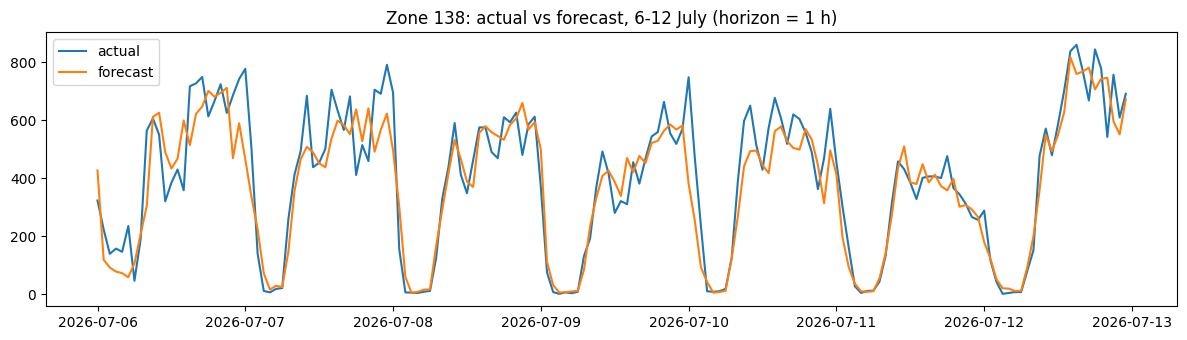

In [7]:
def wape_by(col):
    g = v.groupby(col)[["abs_err", "trips"]].sum()
    return (100 * g["abs_err"] / g["trips"]).round(1)


print("WAPE % by hour of day:\n", wape_by("hour_of_day").to_string())
print("\nWAPE % by day of week (0 = Monday):\n", wape_by("day_of_week").to_string())

# zones that contribute the most error, and their own WAPE
z = v.groupby(["zone_id", "Zone"])[["abs_err", "trips"]].sum()
z["WAPE_%"] = (100 * z["abs_err"] / z["trips"]).round(1)
z["share_of_total_error_%"] = (100 * z["abs_err"] / z["abs_err"].sum()).round(2)
print("\nTop 10 zones by share of total error:\n",
      z.sort_values("share_of_total_error_%", ascending=False).head(10))

# one picture: actual vs forecast for the busiest zone, one week of July
zid = train.groupby("zone_id")["trips"].sum().idxmax()
s = v[(v["zone_id"] == zid) & (v["hour"] >= "2026-07-06") & (v["hour"] < "2026-07-13")]
plt.figure(figsize=(12, 3.5))
plt.plot(s["hour"], s["trips"], label="actual")
plt.plot(s["hour"], s["pred"], label="forecast")
plt.title(f"Zone {zid}: actual vs forecast, 6-12 July (horizon = {H} h)")
plt.legend(); plt.tight_layout(); plt.show()

In [8]:
# Which days are hardest? (the July 4 weekend stands out in the README)
daily = v.groupby(v["hour"].dt.date)[["abs_err", "trips"]].sum()
print("WAPE % by day:\n", (100 * daily["abs_err"] / daily["trips"]).round(1).to_string())

WAPE % by day:
 hour
2026-07-01    11.8
2026-07-02    11.6
2026-07-03    14.3
2026-07-04    15.7
2026-07-05    16.0
2026-07-06    15.1
2026-07-07    12.2
2026-07-08    11.1
2026-07-09    11.7
2026-07-10    10.9
2026-07-11    12.3
2026-07-12    12.6
2026-07-13    11.7
2026-07-14    10.5
2026-07-15    11.8
2026-07-16    10.2
2026-07-17    10.5
2026-07-18    13.9
2026-07-19    13.6
2026-07-20    11.6
2026-07-21    12.6
2026-07-22    11.1
2026-07-23    10.8
2026-07-24    10.3
2026-07-25    11.1
2026-07-26    11.4
2026-07-27    12.1
2026-07-28    12.0
2026-07-29    10.9
2026-07-30    11.5
2026-07-31     9.9


## 6. Prediction intervals (80%)

Two quantile models give a 10% and a 90% forecast. Raw quantile intervals are too narrow or too wide in places, so they
are widened by a **conformal adjustment**: for each of five groups of expected volume (quietest to busiest), the adjustment
is the distance by which the 80th percentile of July's misses falls outside the interval. Bigger zone-hours need bigger
adjustments, which is why the groups are separate.

Steps: raw coverage on July, a check of the calibration (calibrate on the first half of July, test on the second half),
then the final calibration on all of July for use in section 7.

In [9]:
q_params = dict(learning_rate=0.1, num_leaves=63, min_data_in_leaf=100, feature_fraction=0.8,
                bagging_fraction=0.8, bagging_freq=1, seed=42, verbose=-1)

q_models, q_valid = {}, {}
for name, alpha in {"lo": 0.1, "hi": 0.9}.items():
    q_models[name] = lgb.train({**q_params, "objective": "quantile", "alpha": alpha}, dtrain,
                               num_boost_round=500, valid_sets=[dvalid],
                               callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
    q_valid[name] = q_models[name].predict(valid[feats], num_iteration=q_models[name].best_iteration)


def to_bounds(q):
    """Lower bound is never negative, and lo <= hi even if the two models cross."""
    return np.clip(np.minimum(q["lo"], q["hi"]), 0, None), np.maximum(q["lo"], q["hi"])


lo_valid, hi_valid = to_bounds(q_valid)

vi = valid.assign(pred=pred_valid, lo=lo_valid, hi=hi_valid).reset_index(drop=True)
vi["inside"] = (vi["trips"] >= vi["lo"]) & (vi["trips"] <= vi["hi"])
print(f"Raw coverage on July: {100 * vi['inside'].mean():.1f}%  (target: 80%)")
print(f"Average interval width: {(vi['hi'] - vi['lo']).mean():.1f} trips "
      f"(average demand per zone-hour: {vi['trips'].mean():.1f})")
raw_segments = {"airports": vi["is_airport"] == 1,
                "top-20 zones": vi["zone_id"].isin(top20),
                "all other zones": ~vi["zone_id"].isin(top20),
                "holidays": vi["is_holiday"] == 1}
print(pd.Series({k: round(100 * vi.loc[m, "inside"].mean(), 1) for k, m in raw_segments.items()},
                name="coverage_%").to_string())

Training until validation scores don't improve for 50 rounds
[100]	valid_0's quantile: 2.15018
[200]	valid_0's quantile: 2.06602
[300]	valid_0's quantile: 2.02732
[400]	valid_0's quantile: 2.01447
[500]	valid_0's quantile: 2.00667
Did not meet early stopping. Best iteration is:
[500]	valid_0's quantile: 2.00667
Training until validation scores don't improve for 50 rounds
[100]	valid_0's quantile: 2.54566
[200]	valid_0's quantile: 2.49021
[300]	valid_0's quantile: 2.46596
[400]	valid_0's quantile: 2.45296
[500]	valid_0's quantile: 2.44362
Did not meet early stopping. Best iteration is:
[500]	valid_0's quantile: 2.44362
Raw coverage on July: 77.4%  (target: 80%)
Average interval width: 28.9 trips (average demand per zone-hour: 78.4)
airports           64.7
top-20 zones       75.8
all other zones    77.6
holidays           75.3


In [10]:
def fit_adjustments(pred, lo, hi, y, level=0.8):
    """Per volume group (by expected demand), how far to widen the interval so that about `level` of cases fall inside."""
    edges = np.quantile(pred, [0.2, 0.4, 0.6, 0.8])      # 0 = quietest ... 4 = busiest
    group = np.digitize(pred, edges)
    miss = np.maximum(lo - y, y - hi)                    # how far outside; negative = inside
    adj = np.zeros(5)
    for gi in range(5):
        s = miss[group == gi]
        n = len(s)
        adj[gi] = np.quantile(s, min(1.0, np.ceil((n + 1) * level) / n))
    return edges, adj


def apply_adjustments(pred, lo, hi, edges, adj):
    a = adj[np.digitize(pred, edges)]
    lo2 = np.clip(lo - a, 0, None)
    hi2 = np.maximum(hi + a, lo2)
    return lo2, hi2


# Calibration check: calibrate on 1-15 July, then look at 16-31 July only
cal = vi[vi["hour"] < "2026-07-16"]
chk = vi[vi["hour"] >= "2026-07-16"]
edges_half, adj_half = fit_adjustments(cal["pred"].values, cal["lo"].values, cal["hi"].values, cal["trips"].values)
print("adjustment per volume group (trips):", adj_half.round(1))
lo2, hi2 = apply_adjustments(chk["pred"].values, chk["lo"].values, chk["hi"].values, edges_half, adj_half)
chk = chk.assign(lo2=lo2, hi2=hi2)

chk_segments = {"all zones":       chk["trips"] >= 0,
                "airports":        chk["is_airport"] == 1,
                "top-20 zones":    chk["zone_id"].isin(top20),
                "all other zones": ~chk["zone_id"].isin(top20)}
before = (chk["trips"] >= chk["lo"]) & (chk["trips"] <= chk["hi"])
after = (chk["trips"] >= chk["lo2"]) & (chk["trips"] <= chk["hi2"])
print(pd.DataFrame({"coverage before %": {k: 100 * before[m].mean() for k, m in chk_segments.items()},
                    "coverage after %": {k: 100 * after[m].mean() for k, m in chk_segments.items()}}).round(1))
print("average width before:", round((chk["hi"] - chk["lo"]).mean(), 1),
      "| after:", round((chk["hi2"] - chk["lo2"]).mean(), 1))

adjustment per volume group (trips): [0.  0.3 0.7 1.4 3.6]
                 coverage before %  coverage after %
all zones                     78.3              81.8
airports                      69.2              85.3
top-20 zones                  77.6              81.2
all other zones               78.4              81.9
average width before: 29.2 | after: 31.7


In [11]:
# Final calibration for the August test: all of July
interval_edges, interval_adj = fit_adjustments(pred_valid, lo_valid, hi_valid, valid["trips"].values)
print("final adjustment per volume group (trips):", interval_adj.round(1))

final adjustment per volume group (trips): [0.  0.2 0.4 0.9 2.5]


## 7. August test (run once)

Nothing is tuned from here on: the models and the interval adjustments are fixed from sections 4 and 6.
This section only predicts on August and scores it.

In [12]:
y = test["trips"].values
pred_test = point_model.predict(test[feats], num_iteration=point_model.best_iteration)
q_test = {name: q_models[name].predict(test[feats], num_iteration=q_models[name].best_iteration)
          for name in q_models}
lo_raw, hi_raw = to_bounds(q_test)
lo_cal, hi_cal = apply_adjustments(pred_test, lo_raw, hi_raw, interval_edges, interval_adj)

test_results = {"last value":          score(y, test[f"lag_{H}"]),
                "same hour yesterday": score(y, test["lag_24"]),
                "same hour last week": score(y, test["lag_168"]),
                "LightGBM (Poisson)":  score(y, pred_test)}
print(f"=== AUGUST TEST, horizon = {H} hour(s) ahead ===")
print(pd.DataFrame(test_results).T.round(2).to_string())

test_segments = {"all zones":       np.ones(len(test), bool),
                 "airports":        (test["is_airport"] == 1).values,
                 "top-20 zones":    test["zone_id"].isin(top20).values,
                 "all other zones": ~test["zone_id"].isin(top20).values,
                 "weekends":        (test["day_of_week"] >= 5).values}
inside_raw = (y >= lo_raw) & (y <= hi_raw)
inside_cal = (y >= lo_cal) & (y <= hi_cal)
seg_test = pd.DataFrame({k: {"model WAPE %": wape(y[m], pred_test[m]),
                             "last-week WAPE %": wape(y[m], test["lag_168"].values[m]),
                             "interval coverage % (raw)": 100 * inside_raw[m].mean(),
                             "interval coverage % (calibrated)": 100 * inside_cal[m].mean()}
                         for k, m in test_segments.items()}).T.round(1)
print(seg_test.to_string())
print("average interval width (trips): raw", round((hi_raw - lo_raw).mean(), 1),
      "| calibrated", round((hi_cal - lo_cal).mean(), 1), "| average demand:", round(y.mean(), 1))

base_wape = test_results["same hour last week"]["WAPE %"]
model_wape = test_results["LightGBM (Poisson)"]["WAPE %"]
print(f"Error reduction vs same hour last week: {100 * (base_wape - model_wape) / base_wape:.1f}%")

=== AUGUST TEST, horizon = 1 hour(s) ahead ===
                       MAE   RMSE  WAPE %
last value           15.45  26.66   20.28
same hour yesterday  19.17  38.68   25.15
same hour last week  12.53  24.00   16.44
LightGBM (Poisson)    8.96  16.29   11.76
                 model WAPE %  last-week WAPE %  interval coverage % (raw)  interval coverage % (calibrated)
all zones                11.8              16.4                       78.6                              81.2
airports                 14.6              20.3                       60.9                              88.1
top-20 zones             10.6              15.4                       78.9                              81.3
all other zones          12.1              16.8                       78.6                              81.2
weekends                 11.3              15.7                       79.8                              82.3
average interval width (trips): raw 28.2 | calibrated 29.8 | average demand: 76.2
Error r

## 8. Driver-allocation simulation

In each hour, assume the city has as many available drivers as there were trips, and split them across zones in
proportion to a forecast. A trip counts as served if a driver is in its zone.

**Assumptions:** supply equals total demand, drivers move instantly and for free, one trip per driver-hour.
This is a simulation of how useful each forecast is for positioning drivers, not a measured business outcome.

In [13]:
def matched_share(df, forecast):
    t = pd.DataFrame({"hour": df["hour"].values, "y": df["trips"].values,
                      "fc": np.clip(np.asarray(forecast, float), 0, None)})
    supply = t.groupby("hour")["y"].transform("sum")                 # drivers available that hour
    fc_sum = t.groupby("hour")["fc"].transform("sum")
    alloc = np.where(fc_sum > 0, supply * t["fc"] / fc_sum, supply / t.groupby("hour")["y"].transform("size"))
    return 100 * np.minimum(t["y"], alloc).sum() / t["y"].sum()


sim = {"even split across zones":  matched_share(test, np.ones(len(test))),
       "same hour yesterday":      matched_share(test, test["lag_24"]),
       "same hour last week":      matched_share(test, test["lag_168"]),
       "LightGBM forecast":        matched_share(test, pred_test),
       "perfect forecast (limit)": matched_share(test, test["trips"])}
sim = pd.DataFrame({"trips with a driver in their zone %": sim})
sim["unmet %"] = 100 - sim.iloc[:, 0]
print(f"=== Allocation simulation, August, forecast made {H} hour(s) ahead ===")
print(sim.round(1).to_string())
base_unmet = sim.loc["same hour last week", "unmet %"]
model_unmet = sim.loc["LightGBM forecast", "unmet %"]
print(f"Unmet demand vs same-hour-last-week: {base_unmet:.1f}% -> {model_unmet:.1f}%  "
      f"({100 * (base_unmet - model_unmet) / base_unmet:.1f}% lower)")

=== Allocation simulation, August, forecast made 1 hour(s) ahead ===
                          trips with a driver in their zone %  unmet %
even split across zones                                  66.4     33.6
same hour yesterday                                      90.9      9.1
same hour last week                                      92.8      7.2
LightGBM forecast                                        94.6      5.4
perfect forecast (limit)                                100.0      0.0
Unmet demand vs same-hour-last-week: 7.2% -> 5.4%  (25.0% lower)


## 9. Save forecasts for the Streamlit app

Writes `august_forecasts_h{H}.parquet`. Run with `H = 1` and `H = 24`, then copy both files into the repository's `data/` folder.

In [15]:
try:                                       # in Colab: save to Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    assert os.path.isdir("/content/drive/MyDrive"), "Drive is not mounted"
    OUT_DIR = "/content/drive/MyDrive/uber_demand"
except ImportError:                        # anywhere else: a local folder
    OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

forecasts = test[["hour", "zone_id", "Zone", "Borough", "trips"]].assign(
    forecast=pred_test, lo80=lo_cal, hi80=hi_cal, last_week=test["lag_168"].values)
forecasts.to_parquet(f"{OUT_DIR}/august_forecasts_h{H}.parquet")
point_model.save_model(f"{OUT_DIR}/point_model_h{H}.txt")
print("saved for H =", H, "->", sorted(os.listdir(OUT_DIR)))

Mounted at /content/drive
saved for H = 1 -> ['august_forecasts_h1.parquet', 'august_forecasts_h24.parquet', 'point_model_h1.txt', 'point_model_h24.txt', 'taxi_zone_lookup.csv', 'uber_hourly_2026-01.parquet', 'uber_hourly_2026-02.parquet', 'uber_hourly_2026-03.parquet', 'uber_hourly_2026-04.parquet', 'uber_hourly_2026-05.parquet', 'uber_hourly_2026-06.parquet', 'uber_hourly_2026-07.parquet', 'uber_hourly_2026-08.parquet']


## Appendix: weather experiment (negative result, not used in the final model)

Hourly ERA5 weather for New York City (temperature, precipitation, snowfall, wind) from
[Open-Meteo](https://open-meteo.com/) was added as features and compared with the same model without it, on July.
It did not help. In the README run (`H = 24`) the July WAPE went from 14.93% to 15.31%, and in rainy hours from 16.35% to 18.17%.

Likely reasons (not verified): training covers only January to June, so July heat is outside the training range;
one coarse grid point stands in for the whole city; and observed weather is not a forecast.

The request asks for `unixtime` and converts to New York local time, because the API ignores daylight-saving changes
when given a named timezone. This cell needs internet access.

In [16]:
import requests

r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": 40.7128, "longitude": -74.0060,
    "start_date": "2025-12-31", "end_date": "2026-09-01",
    "hourly": "temperature_2m,precipitation,snowfall,wind_speed_10m",
    "timeformat": "unixtime"}, timeout=120)
r.raise_for_status()
print("units:", r.json()["hourly_units"])

weather = pd.DataFrame(r.json()["hourly"])
weather["hour"] = (pd.to_datetime(weather["time"], unit="s", utc=True)
                   .dt.tz_convert("America/New_York").dt.tz_localize(None))   # NYC local clock, like the TLC data
weather = weather.drop(columns="time").rename(columns={
    "temperature_2m": "temp_c", "precipitation": "precip_mm",
    "snowfall": "snow_cm", "wind_speed_10m": "wind_kmh"})
weather_cols = ["temp_c", "precip_mm", "snow_cm", "wind_kmh"]

# The weather of the hour being predicted is treated as a known input (observed, not forecast), so no shifting
train_w = train.merge(weather, on="hour", how="left")
valid_w = valid.merge(weather, on="hour", how="left")
print("July hours without weather:", valid_w["temp_c"].isna().mean())

# Same settings for both models, so the comparison is fair
fast = dict(objective="poisson", learning_rate=0.1, num_leaves=63, min_data_in_leaf=100,
            feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, seed=42, verbose=-1)


def fit_predict(cols):
    dtr = lgb.Dataset(train_w[cols], train_w["trips"])
    dva = lgb.Dataset(valid_w[cols], valid_w["trips"], reference=dtr)
    m = lgb.train(fast, dtr, num_boost_round=500, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
    return m.predict(valid_w[cols], num_iteration=m.best_iteration)


p_without = fit_predict(feats)
p_with = fit_predict(feats + weather_cols)

weather_segments = {"all hours": valid_w["trips"] >= 0,
                    "airports": valid_w["is_airport"] == 1,
                    "weekends": valid_w["day_of_week"] >= 5,
                    "rainy hours (> 0.2 mm)": valid_w["precip_mm"] > 0.2,
                    "dry hours": valid_w["precip_mm"] <= 0.2}
weather_out = {}
for name, m in weather_segments.items():
    yw = valid_w.loc[m, "trips"]
    weather_out[name] = {"WAPE without weather %": wape(yw, p_without[m.values]),
                         "WAPE with weather %": wape(yw, p_with[m.values]),
                         "share of hours %": 100 * m.mean()}
print(pd.DataFrame(weather_out).T.round(2).to_string())

units: {'time': 'unixtime', 'temperature_2m': '°C', 'precipitation': 'mm', 'snowfall': 'cm', 'wind_speed_10m': 'km/h'}
July hours without weather: 0.0
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's poisson: -298.866
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's poisson: -298.833
                        WAPE without weather %  WAPE with weather %  share of hours %
all hours                                12.18                12.40            100.00
airports                                 15.74                15.95              1.15
weekends                                 13.48                13.85             25.81
rainy hours (> 0.2 mm)                   13.04                13.94             15.59
dry hours                                12.01                12.08             84.41
